NAMA : MICHAEL FIGO SAPUTRA

NIM  : A11.2023.15411

UTS BENGKEL KODING

#TAHAP EDA (EXPLORATORY DATA ANALYSIS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

DATA_DIR = Path('/content/drive/MyDrive/UTS_Bengkod/data')

Mounted at /content/drive


In [2]:
csv_files = sorted(DATA_DIR.rglob("*.csv"))

print("Jumlah file CSV:", len(csv_files))

for file in csv_files:
    df_preview = pd.read_csv(file, nrows=5)

    print("\nNama file:", file.name)
    print("Kolom:", df_preview.columns.tolist())

    display(df_preview)

Jumlah file CSV: 1

Nama file: airline_passenger_satisfaction.csv
Kolom: ['ID', 'Gender', 'Age', 'Customer Type', 'Type of Travel', 'Class', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Satisfaction']


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [3]:
df = pd.read_csv(csv_files[0])

print("Dataset berhasil dimuat!")
print("Jumlah baris dan kolom:", df.shape)

display(df.head())

Dataset berhasil dimuat!
Jumlah baris dan kolom: (129880, 24)


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  object 
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  object 
 4   Type of Travel                          129880 non-null  object 
 5   Class                                   129880 non-null  object 
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  1298

In [5]:
# Statistik deskriptif
display(df.describe(include='all').T)

# Pengelompokan fitur
target = 'Satisfaction'

kategorikal = [
    'Gender',
    'Customer Type',
    'Type of Travel',
    'Class'
]

kontinu = [
    'Age',
    'Flight Distance',
    'Departure Delay',
    'Arrival Delay'
]

rating = [
    col for col in df.columns
    if col not in kategorikal + kontinu + ['ID', target]
]

print("Fitur kategorikal:", kategorikal)
print("Fitur kontinu:", kontinu)
print("Fitur rating:", rating)
print("Jumlah fitur rating:", len(rating))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,129880.0,NaN,NaN,NaN,64940.5,37493.270818,1.0,32470.75,64940.5,97410.25,129880.0
Gender,129880,2,Female,65899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,129880.0,NaN,NaN,NaN,39.427957,15.11936,7.0,27.0,40.0,51.0,85.0
Customer Type,129880,2,Returning,106100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type of Travel,129880,2,Business,89693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,129880,3,Business,62160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flight Distance,129880.0,NaN,NaN,NaN,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Departure Delay,129880.0,NaN,NaN,NaN,14.713713,38.071126,0.0,0.0,0.0,12.0,1592.0
Arrival Delay,129487.0,NaN,NaN,NaN,15.091129,38.46565,0.0,0.0,0.0,13.0,1584.0
Departure and Arrival Time Convenience,129880.0,NaN,NaN,NaN,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0


Fitur kategorikal: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Fitur kontinu: ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
Fitur rating: ['Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']
Jumlah fitur rating: 14


In [6]:
# Menghitung missing values
missing = pd.DataFrame({
    'Missing': df.isnull().sum(),
    'Persentase (%)': df.isnull().mean() * 100
})

display(missing[missing['Missing'] > 0])

# Memeriksa duplikat
print("Duplikat seluruh kolom:", df.duplicated().sum())

print("Duplikat tanpa ID:",
      df.drop(columns=['ID']).duplicated().sum())

print("ID berulang:", df['ID'].duplicated().sum())

,Missing,Persentase (%)
Arrival Delay,393,0.302587


Duplikat seluruh kolom: 0
Duplikat tanpa ID: 0
ID berulang: 0


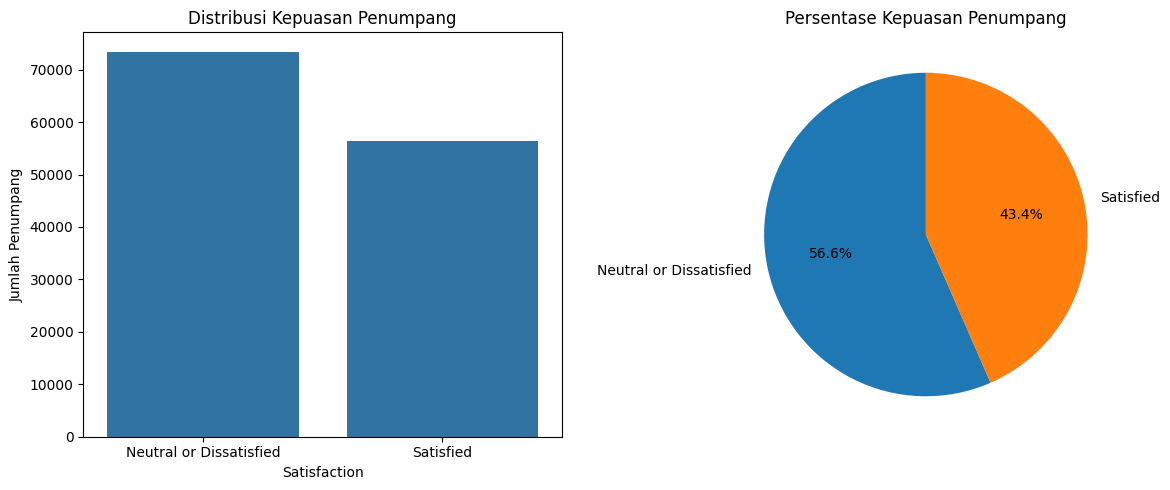

In [7]:
# Menghitung distribusi target
target_counts = df['Satisfaction'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Diagram batang
sns.countplot(
    data=df,
    x='Satisfaction',
    ax=axes[0]
)
axes[0].set_title('Distribusi Kepuasan Penumpang')
axes[0].set_xlabel('Satisfaction')
axes[0].set_ylabel('Jumlah Penumpang')

# Pie chart
axes[1].pie(
    target_counts.values,
    labels=target_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
axes[1].set_title('Persentase Kepuasan Penumpang')

plt.tight_layout()
plt.show()

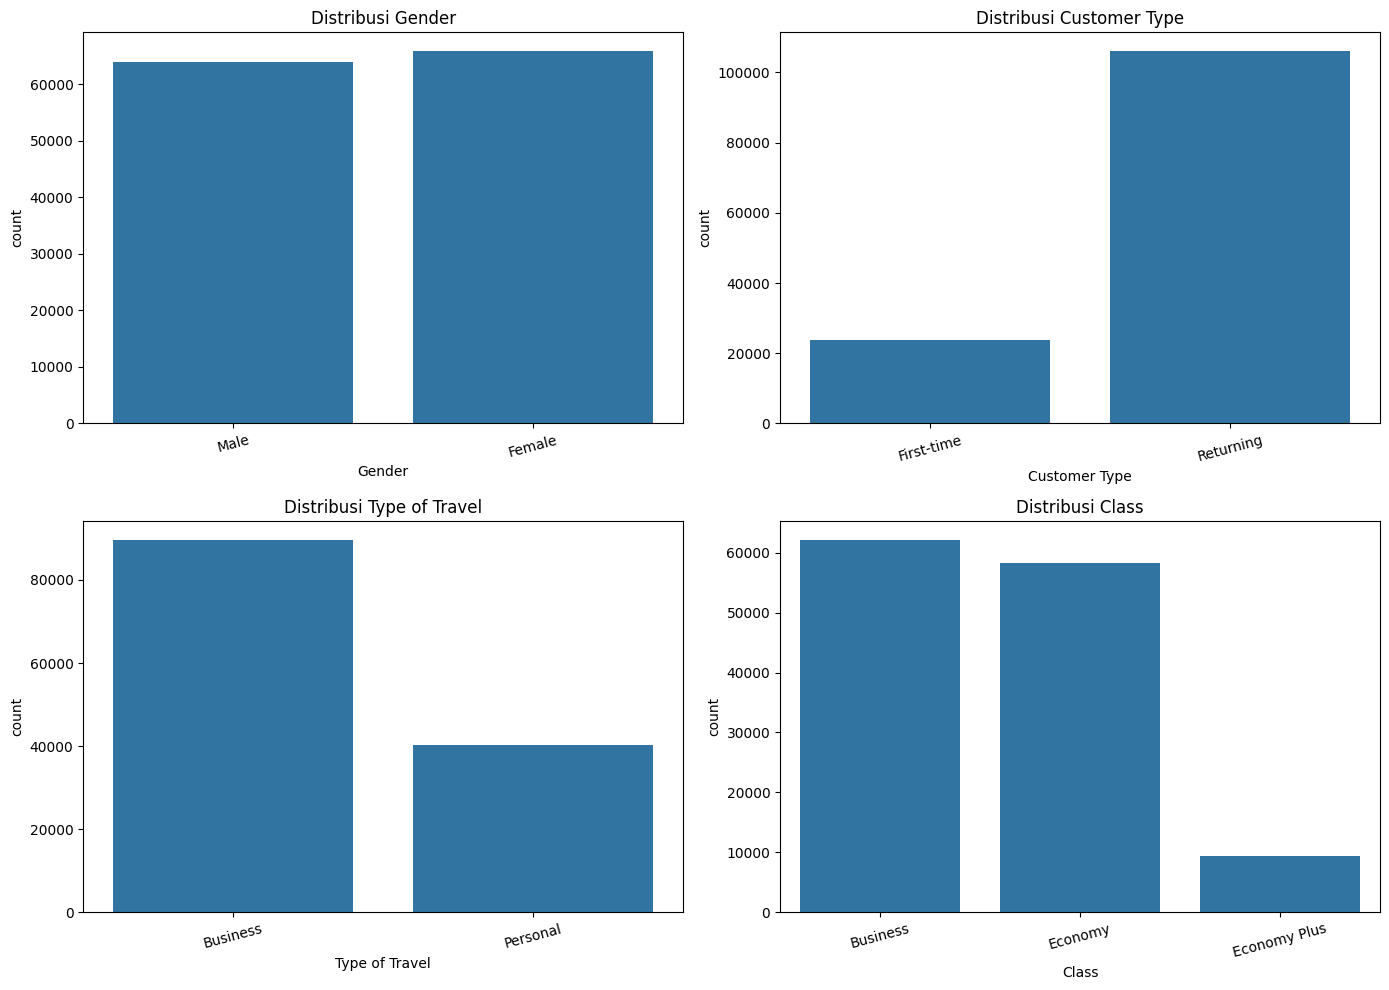

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, kategorikal):
    sns.countplot(
        data=df,
        x=col,
        ax=ax
    )
    ax.set_title(f'Distribusi {col}')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

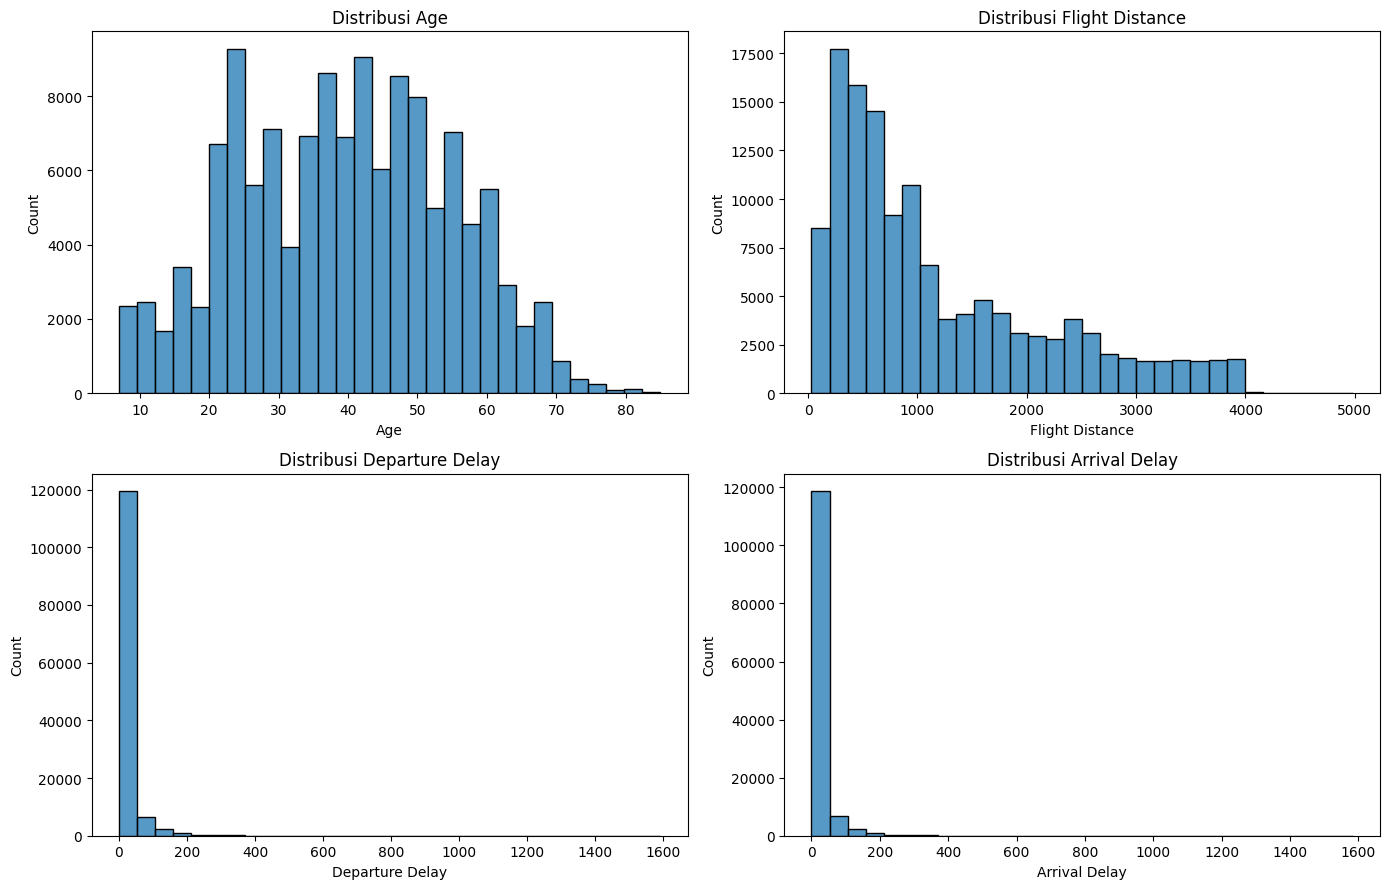

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flat, kontinu):
    sns.histplot(
        data=df,
        x=col,
        bins=30,
        ax=ax
    )
    ax.set_title(f'Distribusi {col}')

plt.tight_layout()
plt.show()

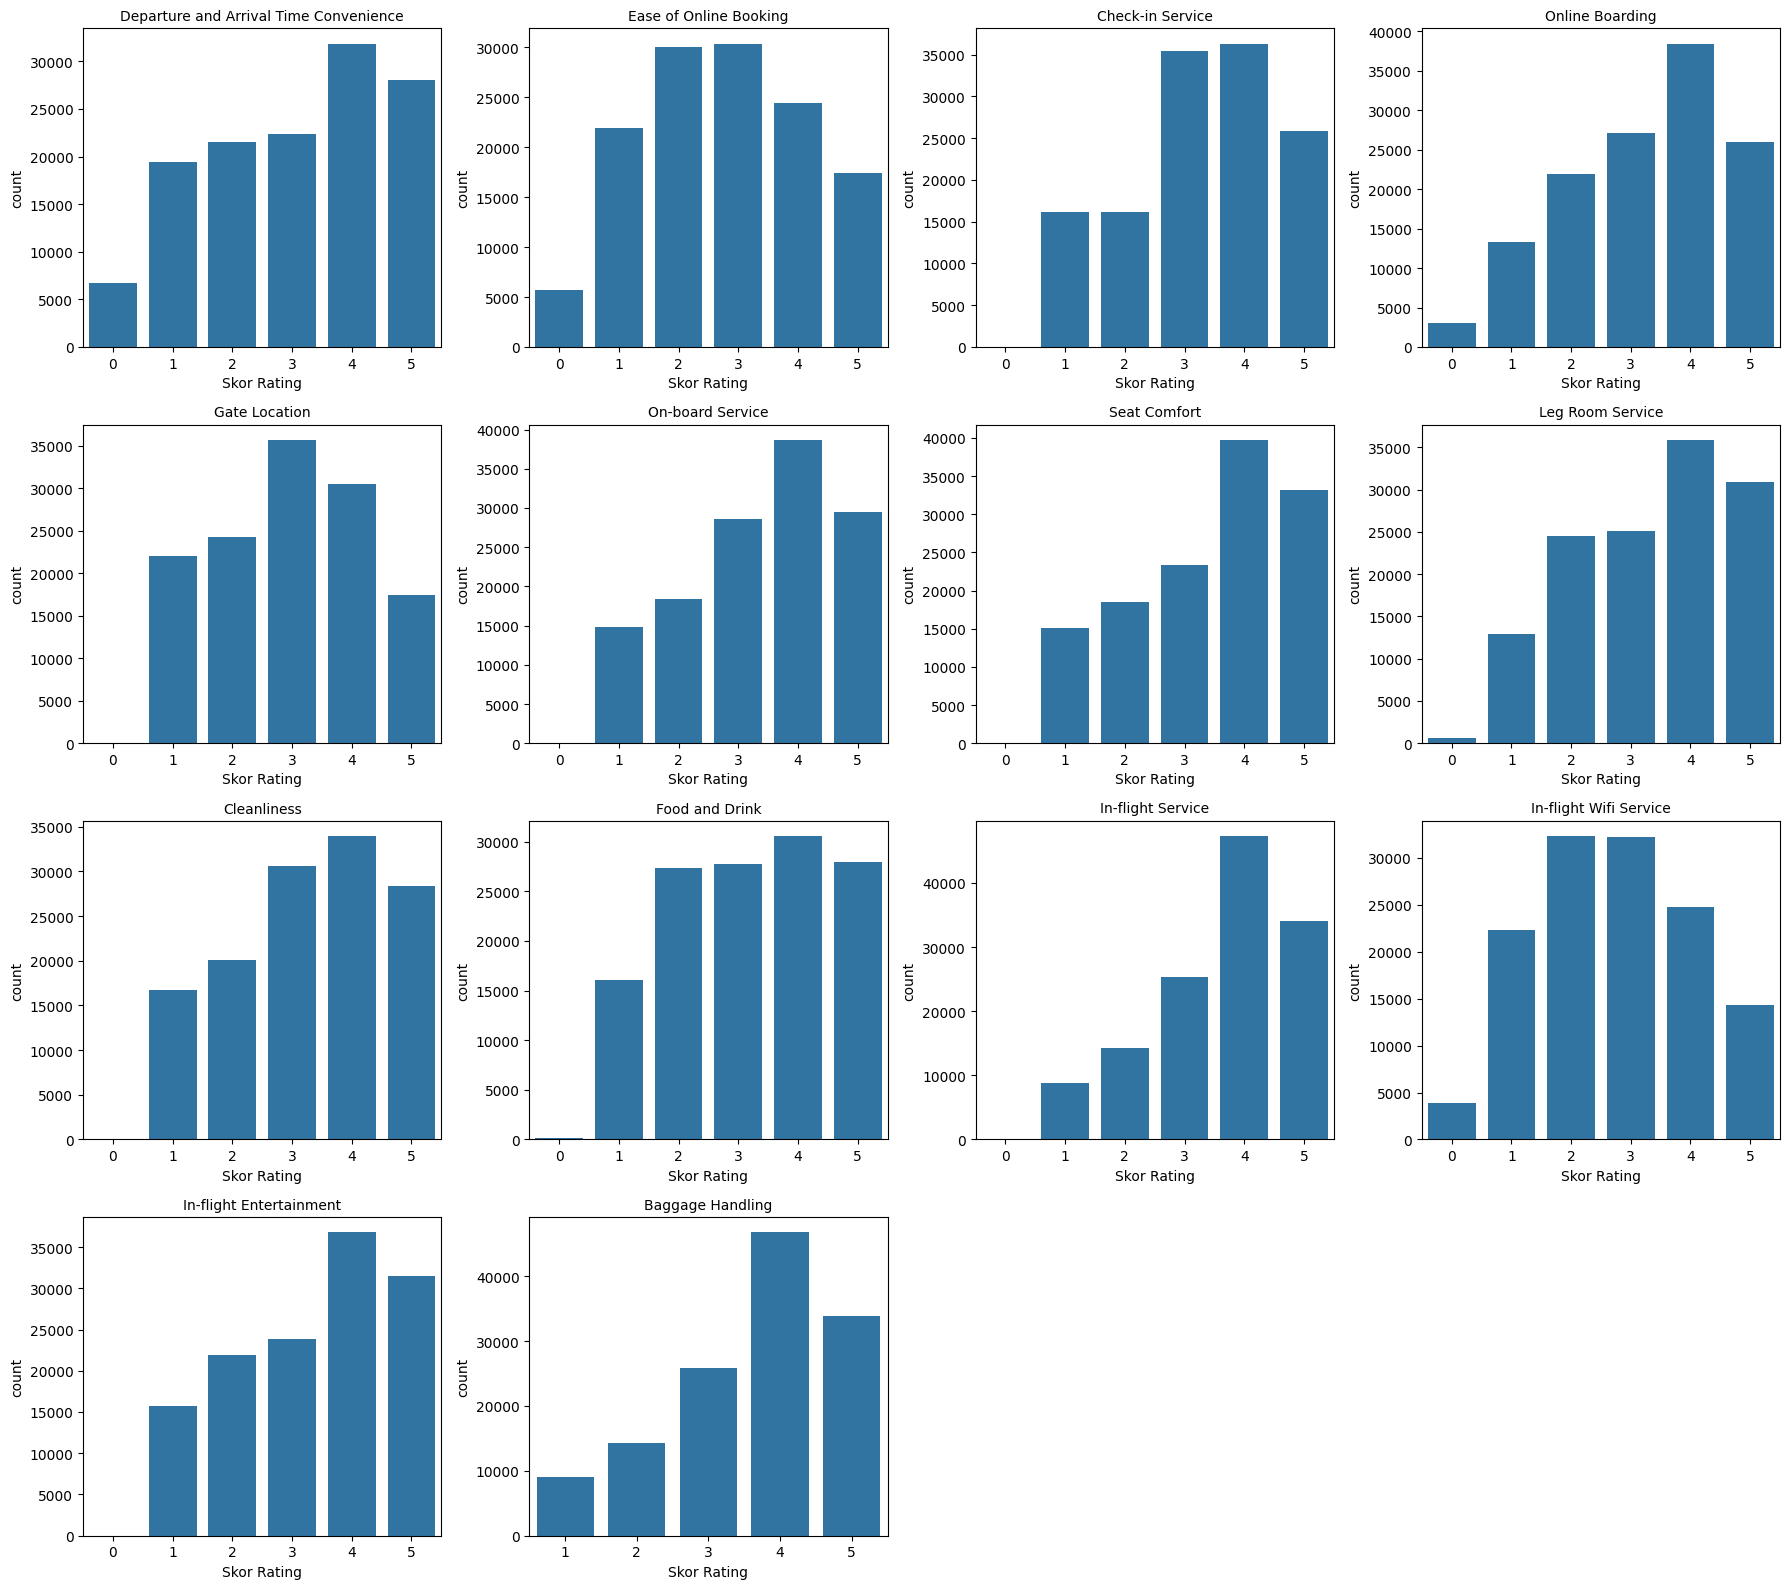

In [10]:
fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, col in zip(axes.flat, rating):
    sns.countplot(
        data=df,
        x=col,
        ax=ax,
        order=sorted(df[col].dropna().unique())
    )
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('Skor Rating')

for ax in axes.flat[len(rating):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

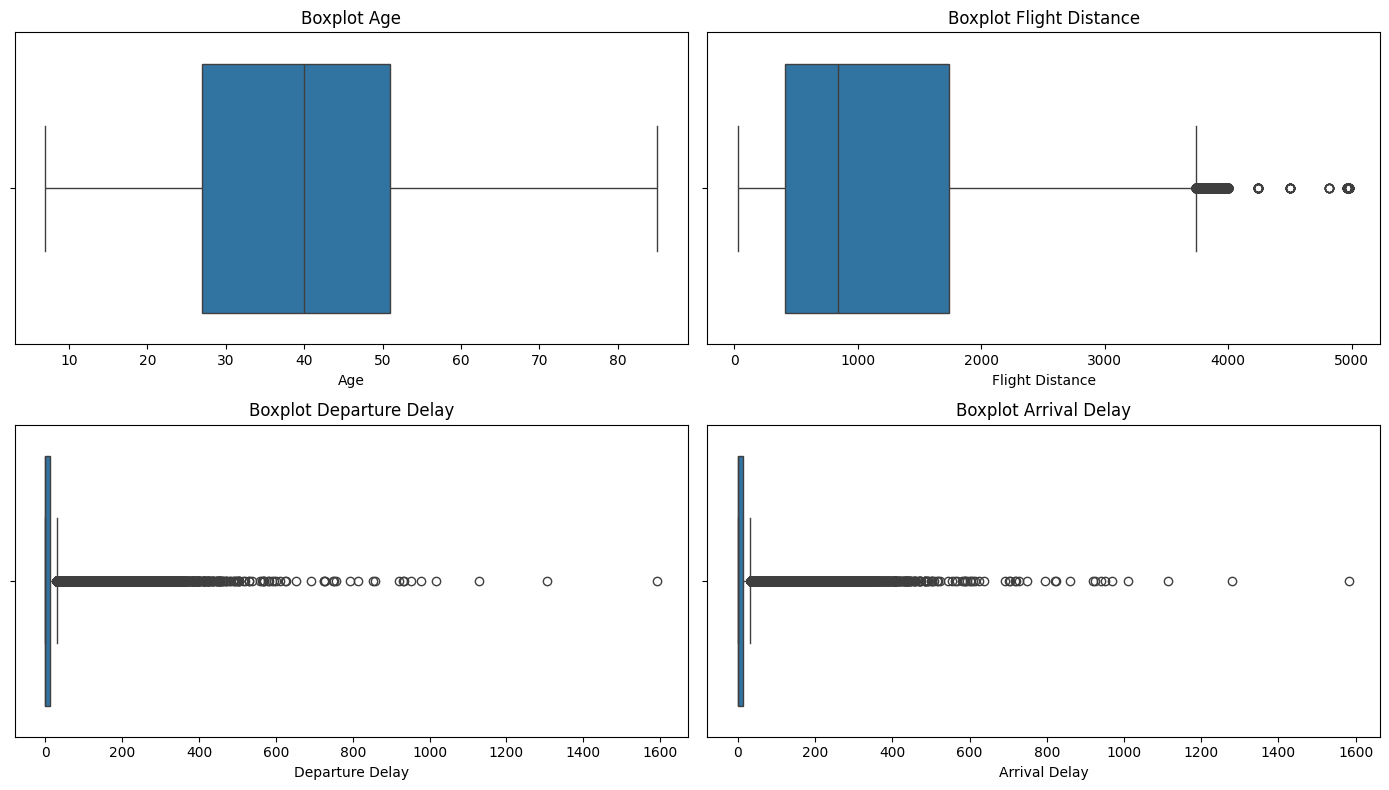

Age: 0 outlier (0.00%)
Flight Distance: 2855 outlier (2.20%)
Departure Delay: 18098 outlier (13.93%)
Arrival Delay: 17492 outlier (13.47%)


In [11]:
# Visualisasi outlier pada fitur kontinu
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.flat, kontinu):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f'Boxplot {col}')

plt.tight_layout()
plt.show()

# Menghitung outlier menggunakan metode IQR
for col in kontinu:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    jumlah = (
        (df[col] < batas_bawah) |
        (df[col] > batas_atas)
    ).sum()

    print(f"{col}: {jumlah} outlier ({jumlah/len(df)*100:.2f}%)")

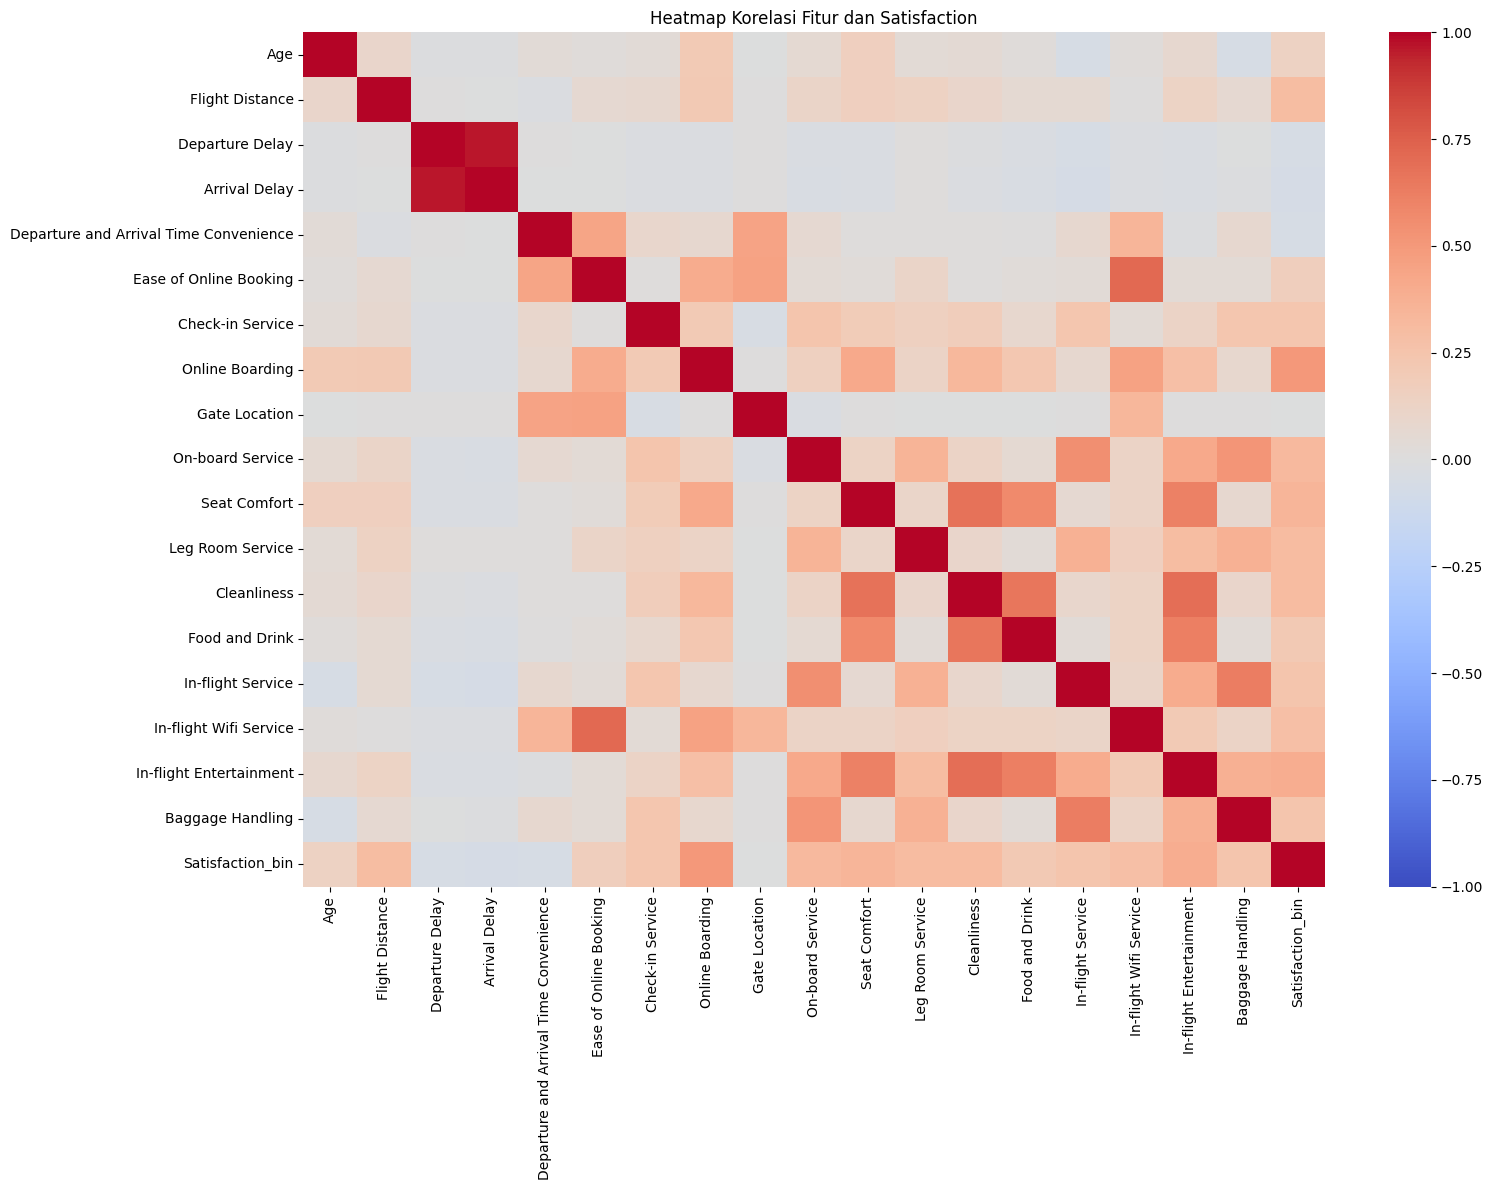

,Korelasi dengan Satisfaction
Online Boarding,0.501749
In-flight Entertainment,0.398234
Seat Comfort,0.348829
On-board Service,0.322205
Leg Room Service,0.312424
Cleanliness,0.307035
Flight Distance,0.298085
In-flight Wifi Service,0.283460
Baggage Handling,0.248680
In-flight Service,0.244918


In [12]:
# Menyiapkan data untuk analisis korelasi
df_corr = df[kontinu + rating].copy()

df_corr['Satisfaction_bin'] = df['Satisfaction'].map({
    'Neutral or Dissatisfied': 0,
    'Satisfied': 1
})

# Menghitung korelasi
corr = df_corr.corr()

# Visualisasi heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    corr,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    annot=False
)

plt.title('Heatmap Korelasi Fitur dan Satisfaction')
plt.tight_layout()
plt.show()

# Melihat fitur yang paling berkorelasi dengan target
korelasi_target = corr['Satisfaction_bin'].drop(
    'Satisfaction_bin'
)

korelasi_target = korelasi_target.reindex(
    korelasi_target.abs().sort_values(
        ascending=False
    ).index
)

display(korelasi_target.to_frame('Korelasi dengan Satisfaction'))

# TAHAP MODELING

In [13]:
from sklearn.model_selection import train_test_split

# Menentukan fitur dan target
X = df.drop(columns=['Satisfaction'])
y = df['Satisfaction'].map({
    'Neutral or Dissatisfied': 0,
    'Satisfied': 1
})

assert y.notna().all(), "Ada label target yang tidak dikenali."

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data Training:", X_train.shape)
print("Data Testing:", X_test.shape)

print("\nDistribusi target training:")
print(y_train.value_counts(normalize=True))

Data Training: (103904, 23)
Data Testing: (25976, 23)

Distribusi target training:
Satisfaction
0    0.565541
1    0.434459
Name: proportion, dtype: float64


In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Membuat validation set dari data training
X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Memisahkan tipe fitur
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

# Preprocessing minimum
preprocessor = ColumnTransformer([
    ('numerik', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    ('kategori', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

# Tiga model klasifikasi
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Model siap digunakan:", list(models.keys()))

Model siap digunakan: ['Logistic Regression', 'Decision Tree', 'Random Forest']


In [15]:
from sklearn.metrics import accuracy_score, f1_score

hasil_model = []
model_terlatih = {}

for nama, algoritma in models.items():

    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', algoritma)
    ])

    pipeline.fit(X_train_model, y_train_model)

    prediksi = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, prediksi)
    f1 = f1_score(y_val, prediksi, average='macro')

    hasil_model.append({
        'Model': nama,
        'Accuracy': accuracy,
        'F1 Macro': f1
    })

    model_terlatih[nama] = pipeline

    print(f"{nama} selesai dilatih.")

hasil_df = pd.DataFrame(hasil_model)
display(hasil_df.sort_values('F1 Macro', ascending=False))

Logistic Regression selesai dilatih.
Decision Tree selesai dilatih.
Random Forest selesai dilatih.


,Model,Accuracy,F1 Macro
2,Random Forest,0.966460,0.965762
1,Decision Tree,0.946153,0.945252
0,Logistic Regression,0.876714,0.874053


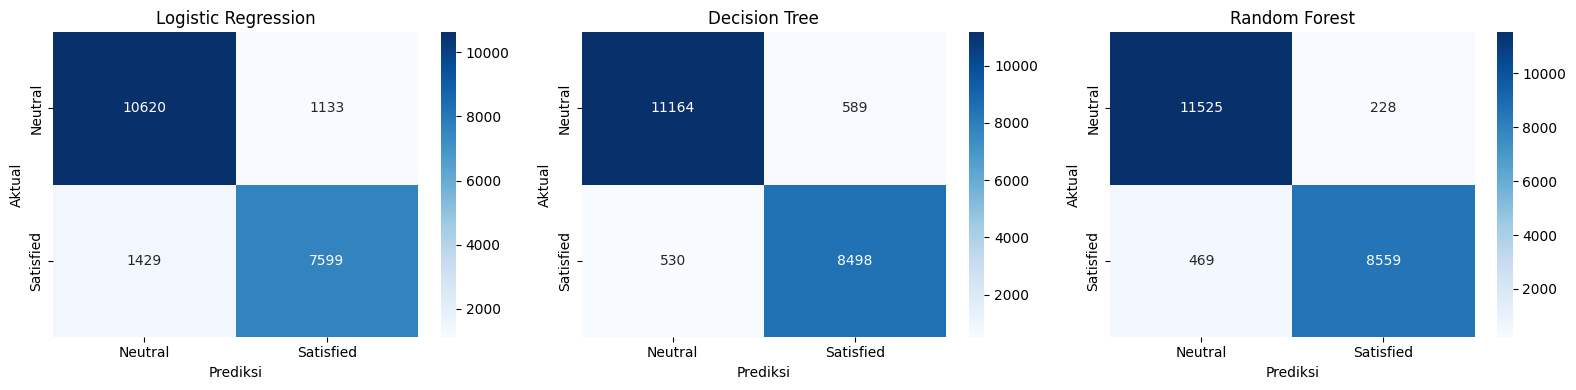

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8767,0.8758,0.8727,0.8741
1,Decision Tree,0.9462,0.9449,0.9456,0.9453
2,Random Forest,0.9665,0.9675,0.9643,0.9658


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

hasil_evaluasi = []

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nama, model) in zip(axes, model_terlatih.items()):

    y_pred = model.predict(X_val)

    hasil_evaluasi.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, average='macro'),
        'Recall': recall_score(y_val, y_pred, average='macro'),
        'F1-Score': f1_score(y_val, y_pred, average='macro')
    })

    cm = confusion_matrix(y_val, y_pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Neutral', 'Satisfied'],
        yticklabels=['Neutral', 'Satisfied'],
        ax=ax
    )

    ax.set_title(nama)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.show()

evaluasi_df = pd.DataFrame(hasil_evaluasi)
display(evaluasi_df.round(4))

# TAHAP PREPROCESSING

In [17]:
# Menghapus ID dari fitur prediktor
X_train_clean = X_train_model.drop(columns=['ID']).copy()
X_val_clean = X_val.drop(columns=['ID']).copy()

# Identifikasi tipe fitur
numeric_features = X_train_clean.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train_clean.select_dtypes(
    include=['object']
).columns.tolist()

print("Jumlah fitur setelah menghapus ID:", X_train_clean.shape[1])

print("\nFitur numerik:")
print(numeric_features)

print("\nFitur kategorikal:")
print(categorical_features)

print("\nMissing values training:")
print(X_train_clean.isnull().sum()[
    X_train_clean.isnull().sum() > 0
])

Jumlah fitur setelah menghapus ID: 22

Fitur numerik:
['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Seat Comfort', 'Leg Room Service', 'Cleanliness', 'Food and Drink', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling']

Fitur kategorikal:
['Gender', 'Customer Type', 'Type of Travel', 'Class']

Missing values training:
Arrival Delay    258
dtype: int64


In [18]:
from sklearn.base import clone

# Preprocessing numerik
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Preprocessing kategorikal
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Menggabungkan preprocessing
preprocessor_clean = ColumnTransformer([
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)
])

# Membuat pipeline untuk ketiga model
models_clean = {
    nama: Pipeline([
        ('preprocessing', clone(preprocessor_clean)),
        ('model', clone(algoritma))
    ])
    for nama, algoritma in models.items()
}

print("Pipeline preprocessing siap untuk:")
print(list(models_clean.keys()))

Pipeline preprocessing siap untuk:
['Logistic Regression', 'Decision Tree', 'Random Forest']


In [19]:
hasil_preprocessing = []
model_preprocessed = {}

for nama, pipeline in models_clean.items():

    # Training model
    pipeline.fit(X_train_clean, y_train_model)

    # Prediksi data validasi
    y_pred = pipeline.predict(X_val_clean)

    hasil_preprocessing.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_val, y_pred),
        'Precision': precision_score(y_val, y_pred, average='macro'),
        'Recall': recall_score(y_val, y_pred, average='macro'),
        'F1-Score': f1_score(y_val, y_pred, average='macro')
    })

    model_preprocessed[nama] = pipeline

hasil_preprocessing_df = pd.DataFrame(hasil_preprocessing)

display(
    hasil_preprocessing_df.sort_values(
        'F1-Score',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.9643,0.9655,0.9620,0.9635
1,Decision Tree,0.9472,0.9462,0.9463,0.9462
0,Logistic Regression,0.8776,0.8769,0.8734,0.8749


In [20]:

# Menangani imbalance menggunakan Random Oversampling

from imblearn.over_sampling import RandomOverSampler

# Membuat objek Random Oversampler
ros = RandomOverSampler(random_state=42)

# Oversampling hanya pada data training
X_train_resampled, y_train_resampled = ros.fit_resample(
    X_train_clean,
    y_train_model
)

# Membandingkan distribusi kelas sebelum dan sesudah
print("Distribusi sebelum oversampling:")
print(pd.Series(y_train_model).value_counts().sort_index())

print("\nDistribusi setelah oversampling:")
print(pd.Series(y_train_resampled).value_counts().sort_index())

print("\nUkuran data sebelum:", X_train_clean.shape)
print("Ukuran data setelah:", X_train_resampled.shape)


Distribusi sebelum oversampling:
Satisfaction
0    47009
1    36114
Name: count, dtype: int64

Distribusi setelah oversampling:
Satisfaction
0    47009
1    47009
Name: count, dtype: int64

Ukuran data sebelum: (83123, 22)
Ukuran data setelah: (94018, 22)


In [21]:
# Training ulang menggunakan Random Oversampling

hasil_oversampling = []
model_oversampling = {}

for nama, pipeline_awal in models_clean.items():

    # Membuat salinan pipeline
    pipeline = clone(pipeline_awal)

    # Melatih model menggunakan data hasil oversampling
    pipeline.fit(X_train_resampled, y_train_resampled)

    # Prediksi menggunakan data validation asli
    y_pred = pipeline.predict(X_val_clean)

    # Menyimpan hasil evaluasi
    hasil_oversampling.append({
        'Model': nama,

        'Accuracy': accuracy_score(y_val, y_pred),

        'Precision Macro': precision_score(
            y_val, y_pred,
            average='macro',
            zero_division=0
        ),

        'Recall Macro': recall_score(
            y_val, y_pred,
            average='macro',
            zero_division=0
        ),

        'F1 Macro': f1_score(
            y_val, y_pred,
            average='macro'
        ),

        'Precision Satisfied': precision_score(
            y_val, y_pred,
            pos_label=1,
            zero_division=0
        ),

        'Recall Satisfied': recall_score(
            y_val, y_pred,
            pos_label=1,
            zero_division=0
        ),

        'F1 Satisfied': f1_score(
            y_val, y_pred,
            pos_label=1
        )
    })

    model_oversampling[nama] = pipeline

    print(f"{nama} selesai dilatih.")

# Menampilkan hasil evaluasi
hasil_oversampling_df = pd.DataFrame(hasil_oversampling)

display(
    hasil_oversampling_df.sort_values(
        'F1 Satisfied',
        ascending=False
    ).round(4)
)

Logistic Regression selesai dilatih.
Decision Tree selesai dilatih.
Random Forest selesai dilatih.


,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Satisfied,Recall Satisfied,F1 Satisfied
2,Random Forest,0.9635,0.9641,0.9617,0.9628,0.9678,0.9476,0.9576
1,Decision Tree,0.9452,0.9439,0.9448,0.9443,0.9332,0.9413,0.9372
0,Logistic Regression,0.8708,0.8681,0.8699,0.8689,0.8434,0.8628,0.8530


In [22]:
# Membandingkan performa kelas Satisfied

hasil_perbandingan = []

for nama in model_preprocessed:

    # Prediksi sebelum oversampling
    pred_before = model_preprocessed[nama].predict(X_val_clean)

    # Prediksi sesudah oversampling
    pred_after = model_oversampling[nama].predict(X_val_clean)

    for kondisi, prediksi in [
        ('Sebelum Oversampling', pred_before),
        ('Sesudah Oversampling', pred_after)
    ]:

        hasil_perbandingan.append({
            'Model': nama,
            'Kondisi': kondisi,

            'Precision Satisfied': precision_score(
                y_val, prediksi, pos_label=1
            ),

            'Recall Satisfied': recall_score(
                y_val, prediksi, pos_label=1
            ),

            'F1 Satisfied': f1_score(
                y_val, prediksi, pos_label=1
            )
        })

perbandingan_df = pd.DataFrame(hasil_perbandingan)

display(perbandingan_df.round(4))

,Model,Kondisi,Precision Satisfied,Recall Satisfied,F1 Satisfied
0,Logistic Regression,Sebelum Oversampling,0.8727,0.8411,0.8566
1,Logistic Regression,Sesudah Oversampling,0.8434,0.8628,0.8530
2,Decision Tree,Sebelum Oversampling,0.9390,0.9394,0.9392
3,Decision Tree,Sesudah Oversampling,0.9332,0.9413,0.9372
4,Random Forest,Sebelum Oversampling,0.9728,0.9442,0.9583
5,Random Forest,Sesudah Oversampling,0.9678,0.9476,0.9576


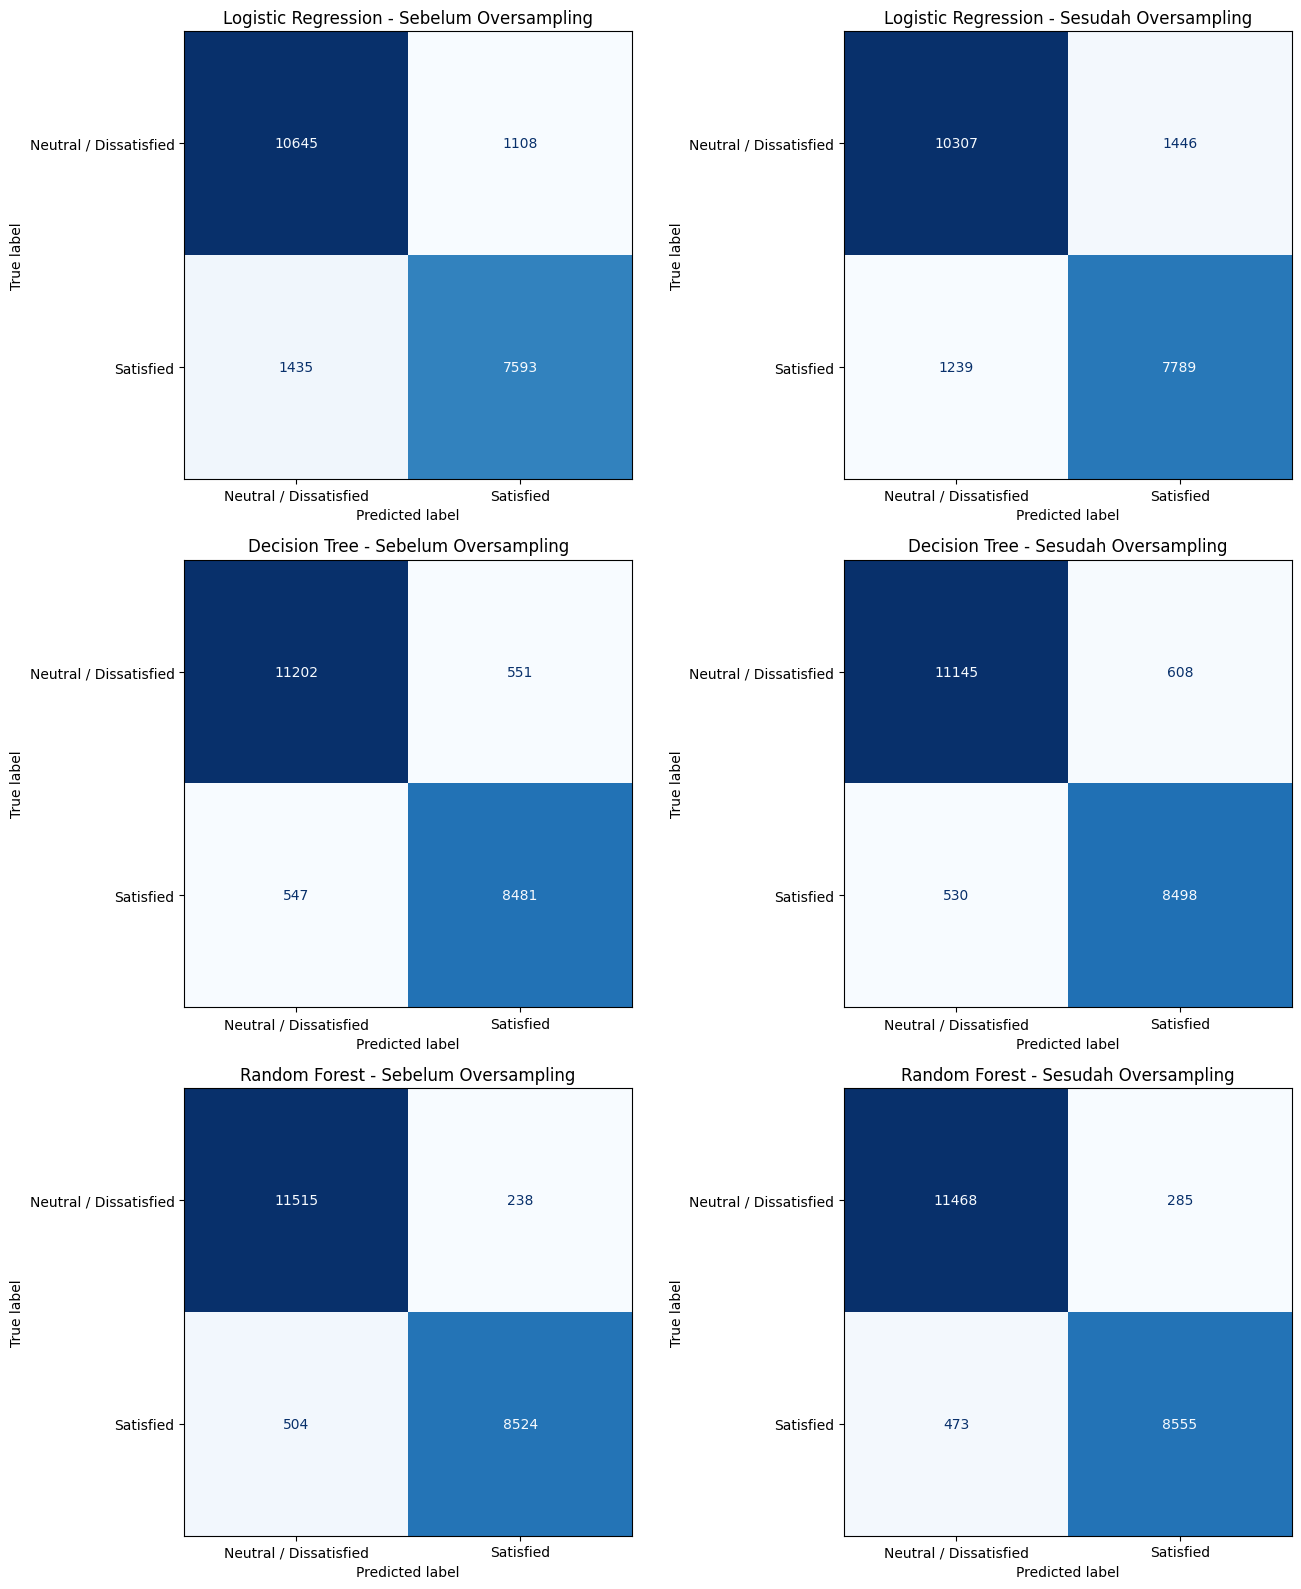

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt

model_perbandingan = {
    'Sebelum Oversampling': model_preprocessed,
    'Sesudah Oversampling': model_oversampling
}

fig, axes = plt.subplots(3, 2, figsize=(14, 16))

for i, nama in enumerate(model_preprocessed):

    for j, (kondisi, kumpulan_model) in enumerate(
        model_perbandingan.items()
    ):

        prediksi = kumpulan_model[nama].predict(X_val_clean)

        cm = confusion_matrix(
            y_val,
            prediksi,
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                'Neutral / Dissatisfied',
                'Satisfied'
            ]
        )

        disp.plot(
            ax=axes[i, j],
            cmap='Blues',
            colorbar=False,
            values_format='d'
        )

        axes[i, j].set_title(
            f'{nama} - {kondisi}'
        )

plt.tight_layout()
plt.show()

In [24]:
# Evaluasi akhir menggunakan data testing

from sklearn.base import clone
from sklearn.metrics import classification_report

# Menghapus ID dari data training dan testing
X_train_final = X_train.drop(columns=['ID']).copy()
X_test_final = X_test.drop(columns=['ID']).copy()

# Melakukan oversampling pada seluruh data training
ros_final = RandomOverSampler(random_state=42)

X_train_final_resampled, y_train_final_resampled = (
    ros_final.fit_resample(X_train_final, y_train)
)

# Membuat dan melatih model final
final_model = clone(models_clean['Random Forest'])

final_model.fit(
    X_train_final_resampled,
    y_train_final_resampled
)

# Prediksi data testing
y_test_pred = final_model.predict(X_test_final)

# Evaluasi model
print("=== HASIL FINAL TESTING ===")

print("Accuracy:",
      round(accuracy_score(y_test, y_test_pred), 4))

print("Precision Macro:",
      round(precision_score(
          y_test, y_test_pred, average='macro'
      ), 4))

print("Recall Macro:",
      round(recall_score(
          y_test, y_test_pred, average='macro'
      ), 4))

print("F1 Macro:",
      round(f1_score(
          y_test, y_test_pred, average='macro'
      ), 4))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=[
        'Neutral / Dissatisfied',
        'Satisfied'
    ]
))

=== HASIL FINAL TESTING ===
Accuracy: 0.9639
Precision Macro: 0.9649
Recall Macro: 0.9617
F1 Macro: 0.9631

Classification Report:
                        precision    recall  f1-score   support

Neutral / Dissatisfied       0.96      0.98      0.97     14690
             Satisfied       0.97      0.94      0.96     11286

              accuracy                           0.96     25976
             macro avg       0.96      0.96      0.96     25976
          weighted avg       0.96      0.96      0.96     25976



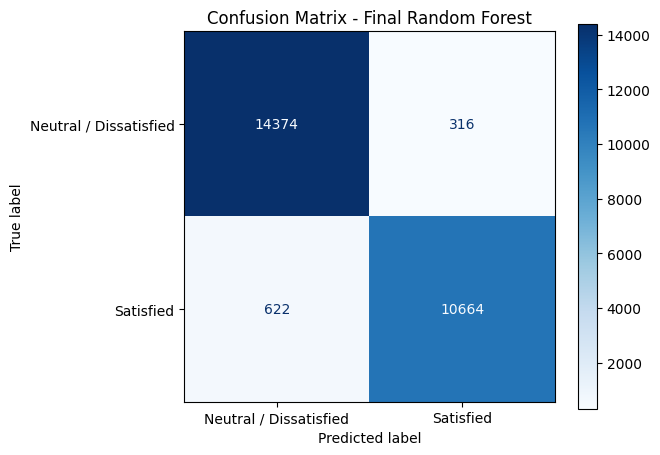

In [25]:
# Confusion Matrix Final Testing

cm_final = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=[
        'Neutral / Dissatisfied',
        'Satisfied'
    ]
)

disp.plot(
    cmap='Blues',
    values_format='d'
)

plt.title('Confusion Matrix - Final Random Forest')
plt.tight_layout()
plt.show()

,Fitur,Importance,Importance (%)
0,Online Boarding,0.1505,15.0506
1,In-flight Wifi Service,0.1455,14.5520
2,Type of Travel,0.1174,11.7358
3,Class,0.1123,11.2328
4,In-flight Entertainment,0.0554,5.5356
5,Customer Type,0.0530,5.2977
6,Seat Comfort,0.0452,4.5153
7,Ease of Online Booking,0.0409,4.0855
8,Leg Room Service,0.0299,2.9874
9,Flight Distance,0.0290,2.8962


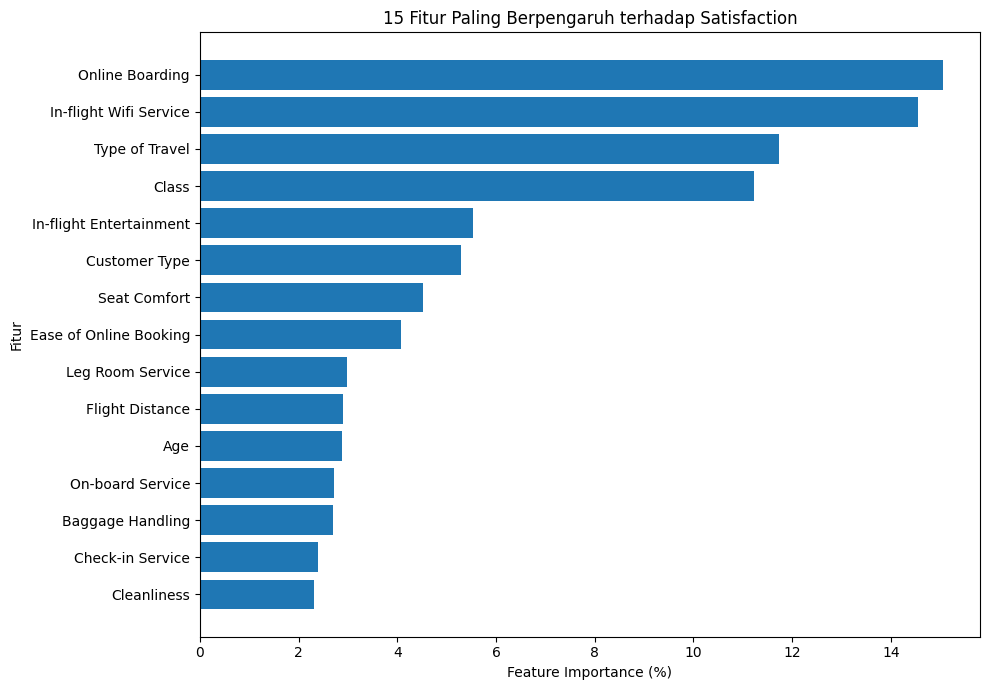

In [26]:
# FEATURE IMPORTANCE - ANALISIS AWAL (VISUALISASI SAJA)
# Seleksi fitur untuk tuning dilakukan ulang di setiap training fold pada Cell 30-31.

# Mengambil model Random Forest yang sudah dilatih
rf_pipeline = model_oversampling['Random Forest']

# Mengambil preprocessing dan model
rf_preprocessor = rf_pipeline.named_steps['preprocessing']
rf_model = rf_pipeline.named_steps['model']

# Mengambil nama fitur setelah encoding
encoded_features = rf_preprocessor.get_feature_names_out()

# Mengambil nilai feature importance
importance_values = rf_model.feature_importances_

# Mengembalikan nama fitur hasil encoding ke nama fitur asli
def nama_fitur_asli(nama_encoded):
    nama = nama_encoded.split('__', 1)[-1]

    semua_fitur = numeric_features + categorical_features

    for fitur in sorted(semua_fitur, key=len, reverse=True):
        if nama == fitur or nama.startswith(fitur + '_'):
            return fitur

    return nama

# Membuat tabel feature importance
feature_importance_df = pd.DataFrame({
    'Fitur': [
        nama_fitur_asli(nama)
        for nama in encoded_features
    ],
    'Importance': importance_values
})

# Menggabungkan importance fitur kategorikal hasil encoding
feature_importance_df = (
    feature_importance_df
    .groupby('Fitur', as_index=False)['Importance']
    .sum()
    .sort_values('Importance', ascending=False)
    .reset_index(drop=True)
)

feature_importance_df['Importance (%)'] = (
    feature_importance_df['Importance'] * 100
)

# Menampilkan hasil
display(feature_importance_df.round(4))

# Visualisasi 15 fitur teratas
top_features = (
    feature_importance_df.head(15)
    .sort_values('Importance (%)')
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Fitur'],
    top_features['Importance (%)']
)

plt.xlabel('Feature Importance (%)')
plt.ylabel('Fitur')
plt.title('15 Fitur Paling Berpengaruh terhadap Satisfaction')

plt.tight_layout()
plt.show()

In [27]:
# FEATURE SELECTION - SELECTOR BERBASIS FITUR ASLI DI DALAM CROSS VALIDATION

from sklearn.base import BaseEstimator, TransformerMixin


class OriginalFeatureImportanceSelector(BaseEstimator, TransformerMixin):
    """
    Memilih fitur asli berdasarkan cumulative feature importance.

    Selector ini akan di-fit ulang pada training fold masing-masing
    ketika digunakan di dalam RandomizedSearchCV.
    """

    def __init__(
        self,
        numeric_transformer,
        categorical_transformer,
        threshold=0.90,
        n_estimators=60,
        random_state=42
    ):
        self.numeric_transformer = numeric_transformer
        self.categorical_transformer = categorical_transformer
        self.threshold = threshold
        self.n_estimators = n_estimators
        self.random_state = random_state

    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            raise TypeError(
                "Input harus berupa pandas DataFrame agar nama fitur asli dapat dipertahankan."
            )

        if not 0 < self.threshold <= 1:
            raise ValueError("threshold harus berada pada rentang (0, 1].")

        # Mengidentifikasi fitur berdasarkan tipe data pada training fold.
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)

        self.numeric_features_ = X.select_dtypes(
            include=[np.number]
        ).columns.tolist()

        self.categorical_features_ = X.select_dtypes(
            include=["object", "category", "string"]
        ).columns.tolist()

        transformers = []

        if self.numeric_features_:
            transformers.append((
                "numeric",
                clone(self.numeric_transformer),
                self.numeric_features_
            ))

        if self.categorical_features_:
            transformers.append((
                "categorical",
                clone(self.categorical_transformer),
                self.categorical_features_
            ))

        if not transformers:
            raise ValueError(
                "Tidak ada fitur numerik atau kategorikal yang dapat diproses."
            )

        # Preprocessing untuk menghitung importance hanya di training fold.
        self.preprocessor_ = ColumnTransformer(
            transformers=transformers,
            remainder="drop"
        )

        X_encoded = self.preprocessor_.fit_transform(X, y)
        encoded_features = self.preprocessor_.get_feature_names_out()

        # Random Forest digunakan sebagai estimator feature importance.
        self.importance_model_ = RandomForestClassifier(
            n_estimators=self.n_estimators,
            random_state=self.random_state,
            class_weight="balanced_subsample",
            n_jobs=1
        )

        self.importance_model_.fit(X_encoded, y)

        # Memetakan setiap kolom hasil encoding ke fitur aslinya.
        def map_to_original_feature(encoded_name):
            name = str(encoded_name).split("__", 1)[-1]

            for feature in sorted(
                self.feature_names_in_.tolist(),
                key=len,
                reverse=True
            ):
                if name == feature or name.startswith(feature + "_"):
                    return feature

            raise ValueError(
                "Fitur hasil encoding tidak dapat dipetakan ke fitur asli: "
                f"{encoded_name}"
            )

        # Menjumlahkan importance seluruh kategori One-Hot Encoding
        # agar seleksi tetap dilakukan pada tingkat fitur asli.
        importance_df = pd.DataFrame({
            "Fitur": [
                map_to_original_feature(name)
                for name in encoded_features
            ],
            "Importance": self.importance_model_.feature_importances_
        })

        importance_df = (
            importance_df
            .groupby("Fitur", as_index=False)["Importance"]
            .sum()
            .sort_values("Importance", ascending=False)
            .reset_index(drop=True)
        )

        total_importance = importance_df["Importance"].sum()

        if total_importance <= 0:
            raise ValueError("Total feature importance bernilai nol.")

        importance_df["Importance (%)"] = (
            importance_df["Importance"] / total_importance * 100
        )

        importance_df["Cumulative Importance (%)"] = (
            importance_df["Importance (%)"].cumsum()
        )

        # Memilih fitur asli sampai cumulative importance mencapai 90%.
        cutoff_index = np.searchsorted(
            importance_df["Cumulative Importance (%)"].to_numpy(),
            self.threshold * 100
        )

        self.feature_importance_df_ = importance_df

        self.selected_features_ = (
            importance_df
            .iloc[:cutoff_index + 1]["Fitur"]
            .tolist()
        )

        return self

    def transform(self, X):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Input harus berupa pandas DataFrame.")

        missing_features = [
            feature
            for feature in self.selected_features_
            if feature not in X.columns
        ]

        if missing_features:
            raise ValueError(
                f"Fitur yang dibutuhkan tidak ditemukan: {missing_features}"
            )

        # Mengembalikan kolom asli, bukan kolom hasil One-Hot Encoding.
        return X.loc[:, self.selected_features_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.selected_features_, dtype=object)


print(
    "OriginalFeatureImportanceSelector siap digunakan. "
    "Seleksi fitur akan di-fit ulang pada setiap training fold."
)


OriginalFeatureImportanceSelector siap digunakan. Seleksi fitur akan di-fit ulang pada setiap training fold.


In [28]:
# HYPERPARAMETER TUNING + FEATURE SELECTION DI DALAM CROSS VALIDATION

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer, make_column_selector
from scipy.stats import loguniform, randint
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

# Preprocessing dinamis setelah feature selection.
# Kolom dipilih berdasarkan tipe data setelah selector memilih fitur asli.
preprocessor_after_selection = ColumnTransformer([
    (
        "numeric",
        clone(numeric_transformer),
        make_column_selector(dtype_include=np.number)
    ),
    (
        "categorical",
        clone(categorical_transformer),
        make_column_selector(
            dtype_include=["object", "category", "string"]
        )
    )
], remainder="drop")


# Membuat pembagian Cross Validation yang mempertahankan proporsi kelas.
cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


# Menentukan rentang hyperparameter setiap model.
param_distributions = {

    "Logistic Regression": {
        "model__C": loguniform(1e-3, 1e2),
        "model__solver": ["lbfgs", "liblinear"]
    },

    "Decision Tree": {
        "model__criterion": ["gini", "entropy"],
        "model__max_depth": [None, 5, 10, 15, 20, 30],
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11)
    },

    "Random Forest": {
        "model__n_estimators": randint(100, 301),
        "model__max_depth": [None, 10, 20, 30],
        "model__min_samples_split": randint(2, 21),
        "model__min_samples_leaf": randint(1, 11),
        "model__max_features": ["sqrt", "log2", None]
    }
}


# Menyimpan hasil tuning dan model terbaik.
hasil_tuning = []
best_models = {}
best_searches = {}


for nama, algoritma in models.items():

    base_model = clone(algoritma)

    # Menghindari parallel processing bertumpuk pada Random Forest.
    if nama == "Random Forest":
        base_model.set_params(n_jobs=1)

    # Seluruh tahapan yang belajar dari data berada di dalam pipeline.
    pipeline = ImbPipeline([

        (
            "feature_selection",
            OriginalFeatureImportanceSelector(
                numeric_transformer=numeric_transformer,
                categorical_transformer=categorical_transformer,
                threshold=0.90,
                n_estimators=60,
                random_state=42
            )
        ),

        (
            "preprocessing",
            clone(preprocessor_after_selection)
        ),

        (
            "oversampling",
            RandomOverSampler(random_state=42)
        ),

        ("model", base_model)

    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_distributions[nama],
        n_iter=6,
        scoring="f1_macro",
        cv=cv_strategy,
        random_state=42,
        n_jobs=-1,
        verbose=1,
        refit=True
    )

    # Data yang diberikan masih berupa data training asli.
    # Feature selection, preprocessing, dan oversampling akan dijalankan
    # secara terpisah pada setiap training fold.
    search.fit(
        X_train_clean,
        y_train_model
    )

    best_models[nama] = search.best_estimator_
    best_searches[nama] = search

    # Evaluasi pada validation set yang tidak di-oversample.
    y_pred = search.predict(X_val_clean)

    hasil_tuning.append({
        "Model": nama,
        "Best CV F1 Macro": search.best_score_,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision Macro": precision_score(
            y_val, y_pred, average="macro"
        ),
        "Recall Macro": recall_score(
            y_val, y_pred, average="macro"
        ),
        "F1 Macro": f1_score(
            y_val, y_pred, average="macro"
        )
    })

    print(f"\n{nama} selesai tuning.")
    print("Parameter terbaik:", search.best_params_)


# Menampilkan hasil tuning.
hasil_tuning_df = pd.DataFrame(hasil_tuning)

display(
    hasil_tuning_df.sort_values(
        "F1 Macro",
        ascending=False
    ).round(4)
)


# Menampilkan hasil seleksi pada refit training data.
# Catatan: selama Cross Validation, selector di-fit ulang pada setiap
# training fold. Tabel ini berasal dari refit pada seluruh X_train_clean.
selector_refit = best_models["Random Forest"].named_steps[
    "feature_selection"
]

print("\nFitur terpilih pada refit seluruh data training tuning:")
print(selector_refit.selected_features_)

print("\nFeature importance berdasarkan fitur asli:")
display(selector_refit.feature_importance_df_.round(4))


Fitting 3 folds for each of 6 candidates, totalling 18 fits

Logistic Regression selesai tuning.
Parameter terbaik: {'model__C': np.float64(0.16949768237884735), 'model__solver': 'lbfgs'}
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Decision Tree selesai tuning.
Parameter terbaik: {'model__criterion': 'entropy', 'model__max_depth': 15, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Fitting 3 folds for each of 6 candidates, totalling 18 fits

Random Forest selesai tuning.
Parameter terbaik: {'model__max_depth': 30, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 13, 'model__n_estimators': 157}


,Model,Best CV F1 Macro,Accuracy,Precision Macro,Recall Macro,F1 Macro
2,Random Forest,0.9569,0.9603,0.9606,0.9585,0.9595
1,Decision Tree,0.9453,0.9488,0.9485,0.9472,0.9478
0,Logistic Regression,0.8631,0.8678,0.8650,0.8669,0.8659



Fitur terpilih pada refit seluruh data training tuning:
['Online Boarding', 'In-flight Wifi Service', 'Type of Travel', 'Class', 'In-flight Entertainment', 'Customer Type', 'Ease of Online Booking', 'Seat Comfort', 'On-board Service', 'Flight Distance', 'Leg Room Service', 'Age', 'Baggage Handling', 'Cleanliness', 'Check-in Service']

Feature importance berdasarkan fitur asli:


,Fitur,Importance,Importance (%),Cumulative Importance (%)
0,Online Boarding,0.1681,16.8094,16.8094
1,In-flight Wifi Service,0.1355,13.5507,30.3601
2,Type of Travel,0.1314,13.1366,43.4967
3,Class,0.0922,9.2201,52.7168
4,In-flight Entertainment,0.0605,6.0504,58.7672
5,Customer Type,0.0513,5.1313,63.8985
6,Ease of Online Booking,0.0419,4.1940,68.0925
7,Seat Comfort,0.0384,3.8364,71.9289
8,On-board Service,0.0309,3.0883,75.0173
9,Flight Distance,0.0298,2.9765,77.9937


In [29]:
# FINAL EVALUATION - TESTING SET

from sklearn.base import clone
from sklearn.metrics import classification_report

# Menghapus ID dari data training dan testing.
X_train_final = X_train.drop(columns=["ID"]).copy()
X_test_final = X_test.drop(columns=["ID"]).copy()

# Menyimpan model dan hasil prediksi.
final_models_tuned = {}
predictions_test = {}
hasil_final_testing = []

# Melatih ulang ketiga model menggunakan seluruh data training.
# Feature selection akan di-fit pada seluruh training set,
# bukan menggunakan fitur yang dipilih sebelum Cross Validation.
for nama, tuned_model in best_models.items():

    model_final = clone(tuned_model)

    # Feature selection, preprocessing, dan oversampling
    # dijalankan otomatis melalui pipeline.
    model_final.fit(
        X_train_final,
        y_train
    )

    # Prediksi menggunakan data testing yang tidak di-oversample.
    y_pred = model_final.predict(X_test_final)

    final_models_tuned[nama] = model_final
    predictions_test[nama] = y_pred

    hasil_final_testing.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision Macro": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Recall Macro": recall_score(
            y_test, y_pred, average="macro"
        ),
        "F1 Macro": f1_score(
            y_test, y_pred, average="macro"
        )
    })

    print(f"\n{nama} selesai diuji.")

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Neutral / Dissatisfied",
            "Satisfied"
        ]
    ))

    selector_final = model_final.named_steps["feature_selection"]
    print("Fitur terpilih pada seluruh data training:", selector_final.selected_features_)


# Menampilkan perbandingan hasil testing.
hasil_final_testing_df = pd.DataFrame(hasil_final_testing)

display(
    hasil_final_testing_df.sort_values(
        "F1 Macro",
        ascending=False
    ).round(4)
)



Logistic Regression selesai diuji.
                        precision    recall  f1-score   support

Neutral / Dissatisfied       0.89      0.88      0.88     14690
             Satisfied       0.84      0.86      0.85     11286

              accuracy                           0.87     25976
             macro avg       0.87      0.87      0.87     25976
          weighted avg       0.87      0.87      0.87     25976

Fitur terpilih pada seluruh data training: ['Online Boarding', 'In-flight Wifi Service', 'Type of Travel', 'Class', 'In-flight Entertainment', 'Customer Type', 'Ease of Online Booking', 'Seat Comfort', 'Leg Room Service', 'Age', 'On-board Service', 'Flight Distance', 'Cleanliness', 'Baggage Handling', 'Check-in Service']

Decision Tree selesai diuji.
                        precision    recall  f1-score   support

Neutral / Dissatisfied       0.95      0.96      0.95     14690
             Satisfied       0.94      0.94      0.94     11286

              accuracy        

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro
2,Random Forest,0.9601,0.9606,0.9582,0.9593
1,Decision Tree,0.9478,0.9473,0.9465,0.9469
0,Logistic Regression,0.8697,0.8670,0.8686,0.8677


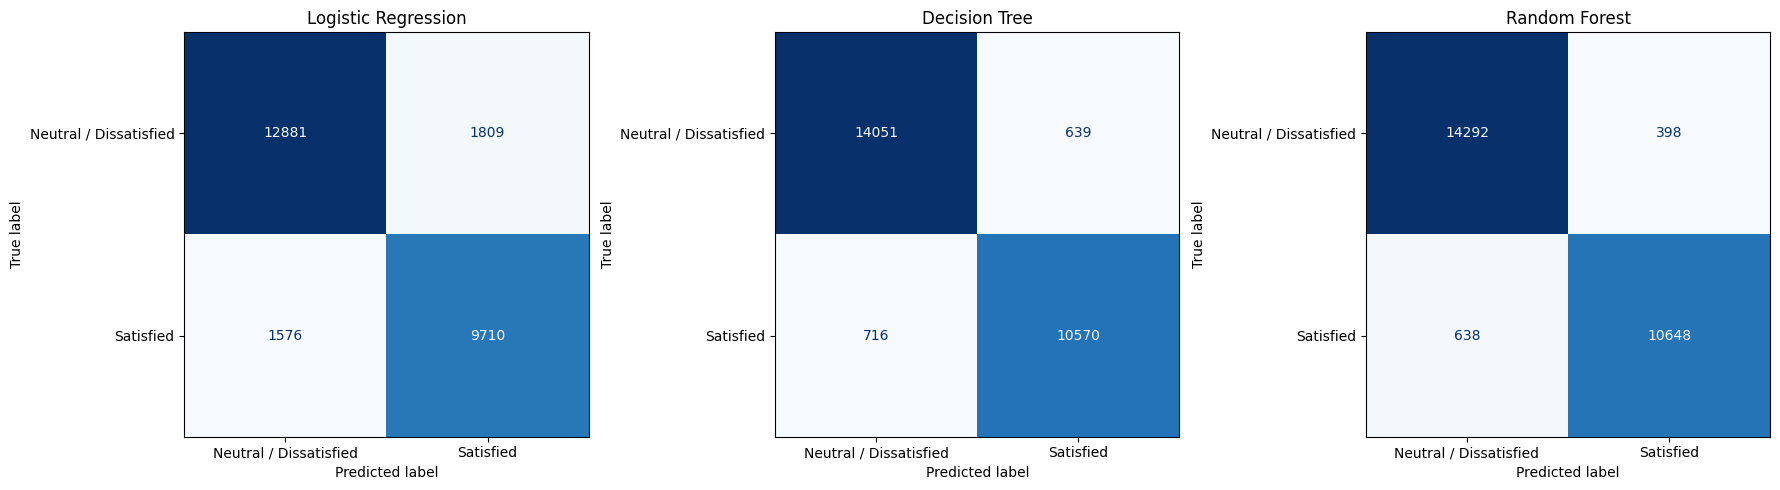

In [30]:

# VISUALISASI CONFUSION MATRIX FINAL TESTING

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (nama, y_pred) in zip(
    axes,
    predictions_test.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            'Neutral / Dissatisfied',
            'Satisfied'
        ]
    )

    disp.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False,
        values_format='d'
    )

    ax.set_title(nama)

plt.tight_layout()
plt.show()


,Model,Accuracy Sebelum,F1 Macro Sebelum,Accuracy Sesudah,F1 Macro Sesudah,Perubahan F1 Macro
0,Logistic Regression,0.8708,0.8689,0.8678,0.8659,-0.0030
1,Decision Tree,0.9452,0.9443,0.9488,0.9478,0.0035
2,Random Forest,0.9635,0.9628,0.9603,0.9595,-0.0033


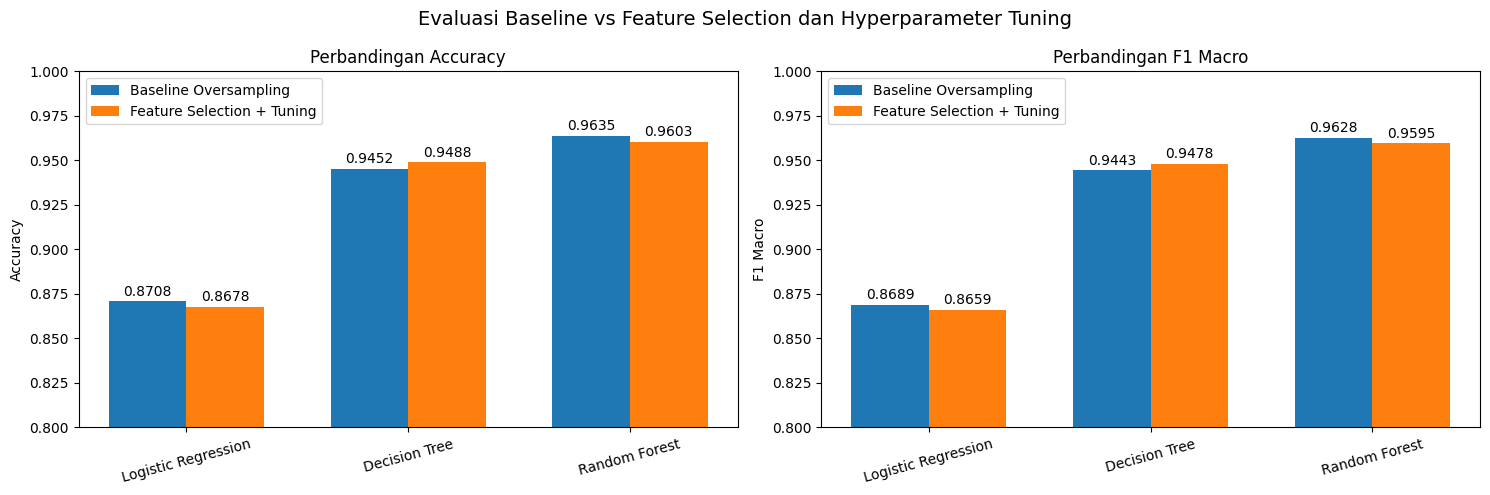

In [31]:
# PERBANDINGAN BASELINE OVERSAMPLING VS FEATURE SELECTION + TUNING

# Kedua hasil menggunakan validation set yang sama (X_val_clean, y_val).
# Baseline: model setelah Random Oversampling.
# Optimasi: feature selection di dalam CV + RandomizedSearchCV.

hasil_baseline = hasil_oversampling_df[
    ["Model", "Accuracy", "F1 Macro"]
].copy()

hasil_optimasi = hasil_tuning_df[
    ["Model", "Accuracy", "F1 Macro"]
].copy()

hasil_perbandingan = hasil_baseline.merge(
    hasil_optimasi,
    on="Model",
    suffixes=(" Sebelum", " Sesudah")
)

# Menghitung perubahan F1 Macro.
hasil_perbandingan["Perubahan F1 Macro"] = (
    hasil_perbandingan["F1 Macro Sesudah"]
    - hasil_perbandingan["F1 Macro Sebelum"]
)

display(hasil_perbandingan.round(4))


# Visualisasi perbandingan.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(hasil_perbandingan))
width = 0.35

# Grafik Accuracy.
bars1 = axes[0].bar(
    x - width/2,
    hasil_perbandingan["Accuracy Sebelum"],
    width,
    label="Baseline Oversampling"
)

bars2 = axes[0].bar(
    x + width/2,
    hasil_perbandingan["Accuracy Sesudah"],
    width,
    label="Feature Selection + Tuning"
)

axes[0].set_title("Perbandingan Accuracy")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(x)
axes[0].set_xticklabels(
    hasil_perbandingan["Model"],
    rotation=15
)
axes[0].set_ylim(0.80, 1.00)
axes[0].legend()

axes[0].bar_label(bars1, fmt="%.4f", padding=2)
axes[0].bar_label(bars2, fmt="%.4f", padding=2)


# Grafik F1 Macro.
bars3 = axes[1].bar(
    x - width/2,
    hasil_perbandingan["F1 Macro Sebelum"],
    width,
    label="Baseline Oversampling"
)

bars4 = axes[1].bar(
    x + width/2,
    hasil_perbandingan["F1 Macro Sesudah"],
    width,
    label="Feature Selection + Tuning"
)

axes[1].set_title("Perbandingan F1 Macro")
axes[1].set_ylabel("F1 Macro")
axes[1].set_xticks(x)
axes[1].set_xticklabels(
    hasil_perbandingan["Model"],
    rotation=15
)
axes[1].set_ylim(0.80, 1.00)
axes[1].legend()

axes[1].bar_label(bars3, fmt="%.4f", padding=2)
axes[1].bar_label(bars4, fmt="%.4f", padding=2)

plt.suptitle(
    "Evaluasi Baseline vs Feature Selection dan Hyperparameter Tuning",
    fontsize=14
)

plt.tight_layout()
plt.show()
